# Using PCRaster data

In [1]:
import earthkit.data as ekd

d = ekd.from_source("sample", "demo.map")
d

demo.map:   0%|          | 0.00/31.5k [00:00<?, ?B/s]

path,/var/folders/93/w0p869rx17q98wxk83gn9ys40000gn/T/tmpiau1snmy/url-b871afdb2e6e96bc518534f19abb5e1a5d7dcd0328d7e5f622c217034dbdc25a.map
size,31.5 KiB
types,numpy


PCRaster currently only supports conversion to a numpy array with ``to_numpy()``. By default, missing values in the raster are represented as ``nan``.

In [3]:
v = d.to_numpy()
v.shape, v.dtype

((100, 80), dtype('float64'))

In [4]:
v

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(100, 80))

The ``missing_to_nan`` keyword controls whether missing values are replaced with ``nan`` or kept using the file's own missing-value representation. This DEM is stored using a scalar (floating point) cell representation, which already uses ``nan`` as its missing-value indicator, so the result is the same in this case. For other cell representations (e.g. boolean or nominal/ordinal rasters, which are stored as integers) the raw values returned would use the format-specific sentinel for missing data instead.

In [5]:
d.to_numpy(missing_to_nan=False)

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(100, 80), dtype=float32)

We can visualise the resulting array with matplotlib. The ``nan`` cells (the area outside of the catchment covered by the DEM) are left blank.

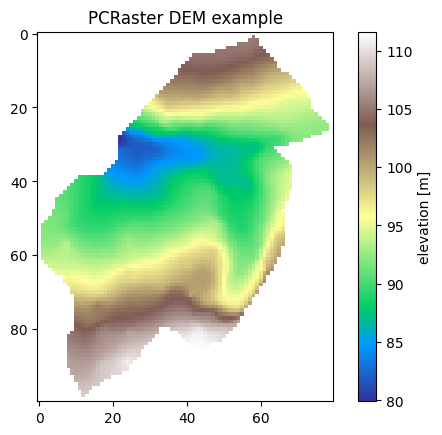

In [6]:
import matplotlib.pyplot as plt

plt.imshow(v, cmap="terrain")
plt.colorbar(label="elevation [m]")
plt.title("PCRaster DEM example")
plt.show()